# Figure 5b. Indirect effects of excitatory neuron *SEC61G* on microglia *trans*-targets

Mediation (structural equation model) of the lead colocalized variant (chr7:54742242:T:C) through excitatory neuron *SEC61G* expression onto each of 25 microglia *trans*-eGenes / *trans*-ePrograms (model M ~ a·X; Y ~ b·M + c′·X; indirect = a·b; lavaan ML/FIML; N = 419 donors; one model per outcome). Points are indirect effects; horizontal bars are **90%** delta-method (Wald) confidence intervals, as in the source table. Orange marks outcomes whose 90% CI excludes 0, which corresponds to nominal two-sided p < 0.1; the stars in the final figure mark the same set. For reference the table also contains BH-adjusted q-values across the 25 tests and the authors' 95% donor-bootstrap intervals: 9/25 have nominal p < 0.05, 6/25 have BH q < 0.05, and 9/25 have 95% bootstrap intervals excluding 0 (MAP4K4, LYST and Program 100 do not).

Input: `data/Figure_5b_sec61g_mediation.rds`.

In [1]:
library(ggplot2)
med <- readRDS("data/Figure_5b_sec61g_mediation.rds")
med[, c("label", "indirect_effect", "ci90_lower", "ci90_upper", "p_value", "bh_q",
        "ci95_boot_lower", "ci95_boot_upper", "ci90_excludes_0")]

label,indirect_effect,ci90_lower,ci90_upper,p_value,bh_q,ci95_boot_lower,ci95_boot_upper,ci90_excludes_0
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
MYO18A,0.11389919,0.0615114726,0.16628690,0.0003486620,0.00871655,0.050398,0.18416,TRUE
ZFP36,-0.18856090,-0.2805021270,-0.09661966,0.0007424448,0.00928056,-0.309397,-0.07759,TRUE
ARHGAP22,0.08602869,0.0380099801,0.13404739,0.0032101435,0.02204246,0.027076,0.14313,TRUE
C20orf194,0.05272198,0.0229994544,0.08244450,0.0035267937,0.02204246,0.018110,0.08756,TRUE
EPHB2,0.07835389,0.0328696144,0.12383816,0.0046038186,0.02301909,0.023703,0.13696,TRUE
NOL4L,0.06513488,0.0227006669,0.10756909,0.0115768457,0.04823686,0.016148,0.11625,TRUE
PTAFR,0.06550824,0.0216291415,0.10938735,0.0140632239,0.05022580,0.019799,0.11449,TRUE
Mic Program 31,-0.20633421,-0.3492132796,-0.06345513,0.0175317316,0.05478666,-0.392569,-0.02450,TRUE
BICRAL,0.04372907,0.0104958183,0.07696233,0.0304385859,0.08455163,0.002385,0.08929,TRUE


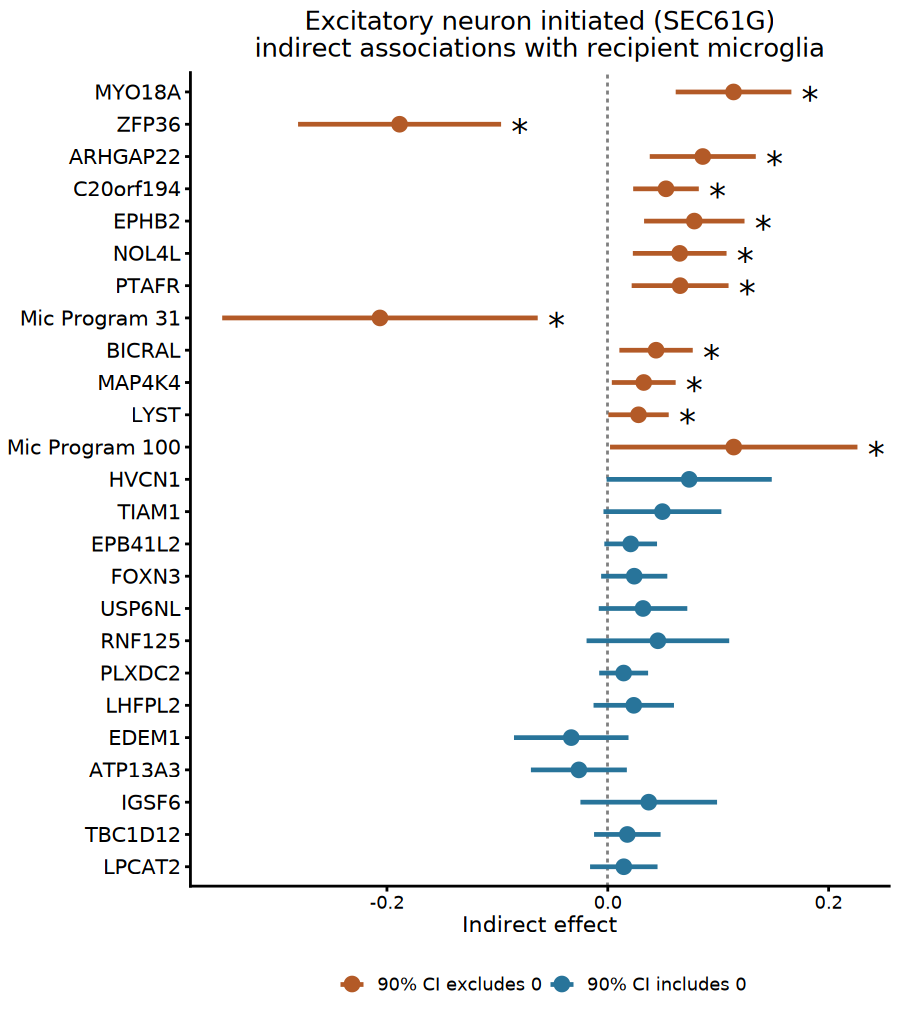

In [2]:
med <- med[order(med$plot_order), ]
med$label <- factor(med$label, levels = rev(med$label))
med$status <- ifelse(med$ci90_excludes_0, "90% CI excludes 0", "90% CI includes 0")

p <- ggplot(med, aes(x = indirect_effect, y = label, colour = status)) +
  geom_vline(xintercept = 0, linetype = 2, colour = "grey50") +
  geom_errorbar(aes(xmin = ci90_lower, xmax = ci90_upper), width = 0, linewidth = 1,
                orientation = "y") +
  geom_point(size = 3.5) +
  geom_text(data = subset(med, ci90_excludes_0), aes(x = ci90_upper, label = "*"),
            hjust = -0.6, vjust = 0.75, size = 7, colour = "black") +
  scale_colour_manual(values = c("90% CI excludes 0" = "#B35A27", "90% CI includes 0" = "#28749A"),
                      name = NULL) +
  labs(title = "Excitatory neuron initiated (SEC61G)\nindirect associations with recipient microglia",
       x = "Indirect effect", y = NULL) +
  theme_classic(base_size = 13) +
  theme(plot.title = element_text(size = 15, hjust = 0.5),
        axis.text.y = element_text(size = 12, face = "italic"),
        legend.position = "bottom")

options(repr.plot.width = 7.5, repr.plot.height = 8.5)
p